# MongoDB EDA — `fleet_operations`

Exploratory analysis of the three MongoDB collections: `delivery_events`, `maintenance_records`, `safety_incidents`.

**Important:** documents are raw CSV rows with **every value stored as a string**, plus Mongo's `_id`. Staging models must `try_cast` everything — this notebook quantifies cast risk and the business signals (on-time, detention, maintenance cost, safety).

> Companion notebook: `mysql_eda.ipynb`.


## 1. Setup


In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.05)

DATA = Path("..") / "data" / "mongo"
if not DATA.exists():
    DATA = Path("data/mongo")
FIGSIZE = (12, 5)
RANDOM = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# All values arrive as strings — keep that honest on read
print("pandas", pd.__version__, "| seaborn", sns.__version__)
print("data dir:", DATA.resolve())


pandas 3.1.1 | seaborn 0.13.2
data dir: C:\Git-Repo\fleet\data\mongo


## 2. Load collections


In [2]:
events = pd.read_csv(DATA / "delivery_events.csv", dtype=str)
maint = pd.read_csv(DATA / "maintenance_records.csv", dtype=str)
safety = pd.read_csv(DATA / "safety_incidents.csv", dtype=str)

for name, df in [("delivery_events", events), ("maintenance_records", maint), ("safety_incidents", safety)]:
    print(f"{name}: {df.shape[0]:,} docs × {df.shape[1]} fields")

display(events.head(3))


delivery_events: 170,820 docs × 12 fields
maintenance_records: 2,920 docs × 13 fields
safety_incidents: 170 docs × 16 fields


,event_id,load_id,trip_id,event_type,facility_id,scheduled_datetime,actual_datetime,detention_minutes,on_time_flag,location_city,location_state,loaded_at
0,EVT00000001,LOAD00000001,TRIP00000001,Pickup,FAC00034,2022-01-01 18:00:00.000000,2022-01-01 20:58:55.918185,0,False,Houston,TX,2026-11-16T06:24:25.384993+00:00
1,EVT00000002,LOAD00000001,TRIP00000001,Delivery,FAC00046,2022-01-02 23:10:55.918185,2022-01-02 21:30:22.142060,230,True,Detroit,MI,2026-11-16T06:24:25.384993+00:00
2,EVT00000003,LOAD00000002,TRIP00000002,Pickup,FAC00015,2022-01-01 18:00:00.000000,2022-01-01 17:37:26.608430,62,True,Kansas City,MO,2026-11-16T06:24:25.384993+00:00


## 3. Data-quality audit (string world)

- Business keys unique?
- How many values fail numeric / datetime casts?
- Which columns are null-ish (empty string vs real null)?


In [3]:
def cast_report(df: pd.DataFrame, name: str, numeric_cols, datetime_cols) -> pd.DataFrame:
    rows = []
    for col in df.columns:
        s = df[col]
        empty = (s.isna() | (s.str.strip() == "") | (s.str.lower() == "nan")).sum()
        row = {"collection": name, "column": col, "empty": int(empty), "dtype_in": str(s.dtype)}
        if col in numeric_cols:
            bad = pd.to_numeric(s, errors="coerce").isna().sum() - empty
            row["cast_fail_numeric"] = int(max(bad, 0))
        if col in datetime_cols:
            bad = pd.to_datetime(s, errors="coerce", format="mixed").isna().sum() - empty
            row["cast_fail_datetime"] = int(max(bad, 0))
        rows.append(row)
    return pd.DataFrame(rows)

event_num = ["detention_minutes"]
event_dt = ["scheduled_datetime", "actual_datetime", "loaded_at"]
maint_num = ["odometer_reading", "labor_hours", "labor_cost", "parts_cost", "total_cost", "downtime_hours"]
maint_dt = ["maintenance_date", "loaded_at"]
safety_num = ["vehicle_damage_cost", "cargo_damage_cost", "claim_amount"]
safety_dt = ["incident_date", "loaded_at"]

report = pd.concat([
    cast_report(events, "delivery_events", event_num, event_dt),
    cast_report(maint, "maintenance_records", maint_num, maint_dt),
    cast_report(safety, "safety_incidents", safety_num, safety_dt),
], ignore_index=True)

display(report)

fail_cols = report.loc[
    (report.get("cast_fail_numeric", 0).fillna(0) > 0) | (report.get("cast_fail_datetime", 0).fillna(0) > 0)
]
print("Columns with cast failures:", len(fail_cols))


,collection,column,empty,dtype_in,cast_fail_datetime,cast_fail_numeric
0,delivery_events,event_id,0,str,NaN,NaN
1,delivery_events,load_id,0,str,NaN,NaN
2,delivery_events,trip_id,0,str,NaN,NaN
3,delivery_events,event_type,0,str,NaN,NaN
4,delivery_events,facility_id,0,str,NaN,NaN
5,delivery_events,scheduled_datetime,0,str,0.00,NaN
6,delivery_events,actual_datetime,0,str,0.00,NaN
7,delivery_events,detention_minutes,0,str,NaN,0.00
8,delivery_events,on_time_flag,0,str,NaN,NaN
9,delivery_events,location_city,0,str,NaN,NaN


Columns with cast failures: 0


In [4]:
# Keys and duplicates
for name, df, key in [
    ("delivery_events", events, "event_id"),
    ("maintenance_records", maint, "maintenance_id"),
    ("safety_incidents", safety, "incident_id"),
]:
    print(f"{name}: unique {key}={df[key].nunique():,} / {len(df):,} | dups={df[key].duplicated().sum()}")

# Loaded_at freshness window
for name, df in [("delivery_events", events), ("maintenance_records", maint), ("safety_incidents", safety)]:
    la = pd.to_datetime(df["loaded_at"], errors="coerce")
    print(f"{name} loaded_at: {la.min()} → {la.max()}")


delivery_events: unique event_id=170,820 / 170,820 | dups=0
maintenance_records: unique maintenance_id=2,920 / 2,920 | dups=0
safety_incidents: unique incident_id=170 / 170 | dups=0
delivery_events loaded_at: 2026-11-16 06:24:25.384993+00:00 → 2026-11-16 06:24:25.384993+00:00
maintenance_records loaded_at: 2026-11-16 06:24:26.332985+00:00 → 2026-11-16 06:24:26.332985+00:00
safety_incidents loaded_at: 2026-11-16 06:24:26.359312+00:00 → 2026-11-16 06:24:26.359312+00:00


## 4. Delivery events — on-time and detention

Two events per load (Pickup + Delivery) → 170,820 docs for 85,410 loads.


on_time_flag raw values: {'True': 95095, 'False': 75725}
parsed on_time: {True: 95095, False: 75725}


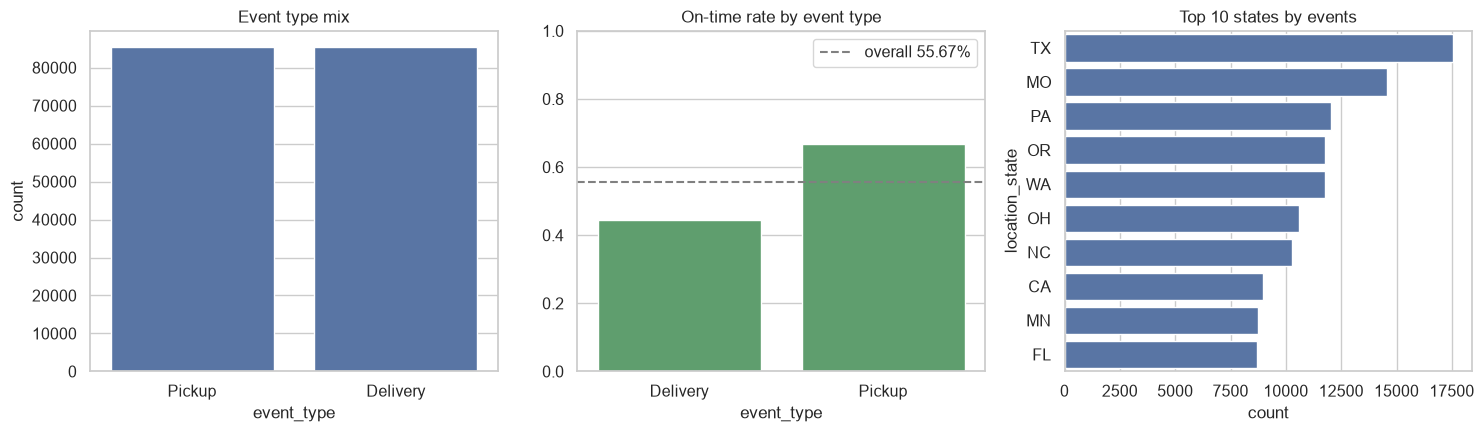

Overall on-time rate: 55.67%  (late: 75,725)


In [5]:
# Light typing for analysis (staging does this in dbt)
for col in ["detention_minutes"]:
    events[col] = pd.to_numeric(events[col], errors="coerce")
events["scheduled_dt"] = pd.to_datetime(events["scheduled_datetime"], errors="coerce")
events["actual_dt"] = pd.to_datetime(events["actual_datetime"], errors="coerce")
events["on_time"] = events["on_time_flag"].str.lower().map({"true": True, "false": False})

print("on_time_flag raw values:", events["on_time_flag"].value_counts(dropna=False).to_dict())
print("parsed on_time:", events["on_time"].value_counts(dropna=False).to_dict())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.countplot(data=events, x="event_type", ax=axes[0], order=["Pickup", "Delivery"])
axes[0].set_title("Event type mix")

ot = events.groupby("event_type")["on_time"].mean()
sns.barplot(x=ot.index, y=ot.values, ax=axes[1], color="#55a868")
axes[1].set_title("On-time rate by event type")
axes[1].set_ylim(0, 1)
axes[1].axhline(ot.mean(), ls="--", color="gray", label=f"overall {ot.mean():.2%}")
axes[1].legend()

sns.countplot(data=events, y="location_state", ax=axes[2],
              order=events["location_state"].value_counts().head(10).index)
axes[2].set_title("Top 10 states by events")
plt.tight_layout()
plt.show()

overall_ot = events["on_time"].mean()
print(f"Overall on-time rate: {overall_ot:.2%}  (late: {(~events['on_time']).sum():,})")


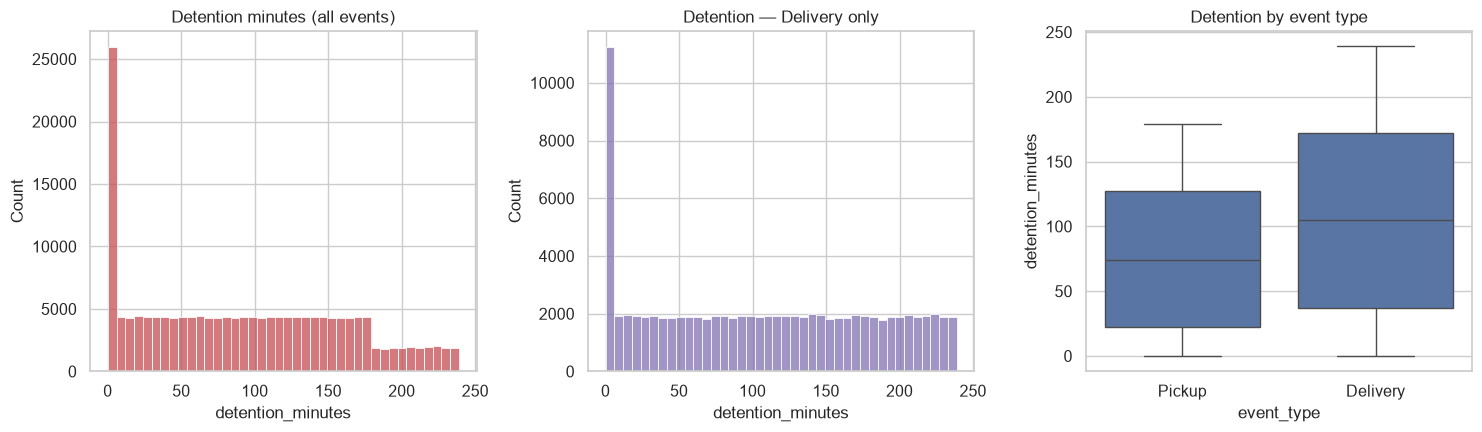

               count   mean   std  min   25%    50%    75%    max
event_type                                                       
Delivery   85,410.00 106.60 75.30 0.00 37.00 105.00 172.00 239.00
Pickup     85,410.00  76.50 57.40 0.00 22.00  74.00 127.00 179.00
Detention > 120 min share: 36.17%


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.histplot(data=events, x="detention_minutes", bins=40, ax=axes[0], color="#c44e52")
axes[0].set_title("Detention minutes (all events)")

det_delivery = events.loc[events["event_type"] == "Delivery", "detention_minutes"]
sns.histplot(data=det_delivery, bins=40, ax=axes[1], color="#8172b2")
axes[1].set_title("Detention — Delivery only")

sns.boxplot(data=events, x="event_type", y="detention_minutes", ax=axes[2], showfliers=False)
axes[2].set_title("Detention by event type")
plt.tight_layout()
plt.show()

print(events.groupby("event_type")["detention_minutes"].describe().round(1))
print("Detention > 120 min share:", f"{(events['detention_minutes'] > 120).mean():.2%}")


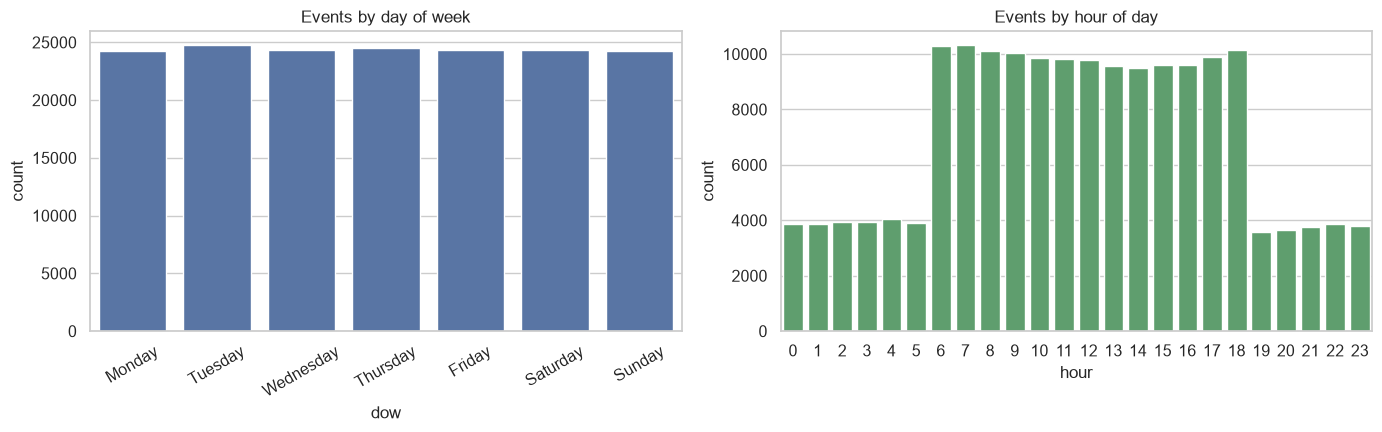

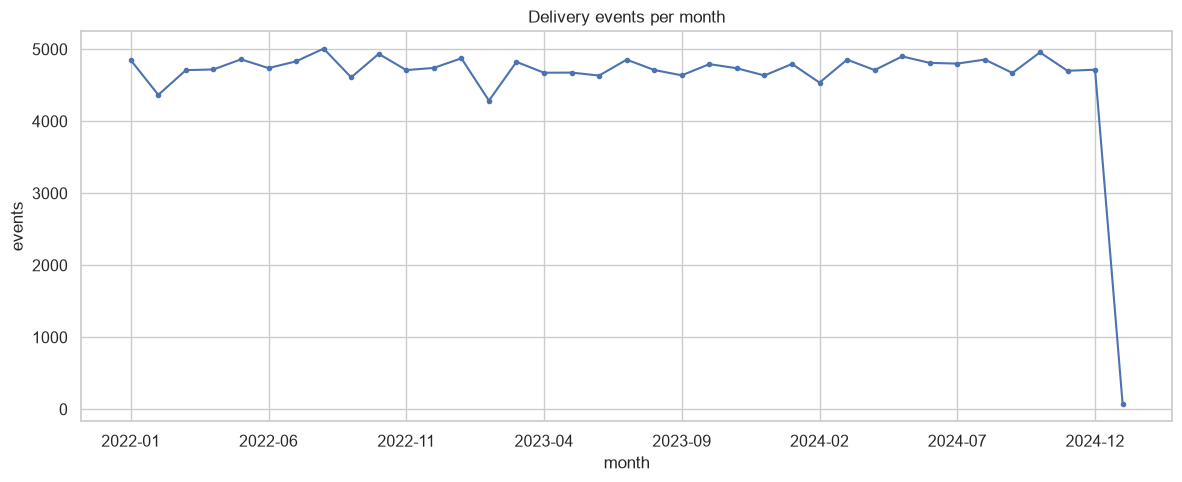

In [7]:
# Temporal pattern — volume by day of week and hour
events["dow"] = events["scheduled_dt"].dt.day_name()
events["hour"] = events["scheduled_dt"].dt.hour
events["month"] = events["scheduled_dt"].dt.to_period("M").astype(str)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order_dow = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.countplot(data=events, x="dow", order=order_dow, ax=axes[0], color="#4c72b0")
axes[0].set_title("Events by day of week")
axes[0].tick_params(axis="x", rotation=30)
sns.countplot(data=events, x="hour", ax=axes[1], color="#55a868")
axes[1].set_title("Events by hour of day")
plt.tight_layout()
plt.show()

monthly_vol = events.groupby("month").size()
ax = monthly_vol.plot(figsize=FIGSIZE, marker="o", markersize=3, color="#4c72b0")
ax.set_title("Delivery events per month")
ax.set_ylabel("events")
plt.tight_layout()
plt.show()


## 5. Maintenance records

Cost and downtime by type — feeds `mart_maintenance_cost_per_mile`.


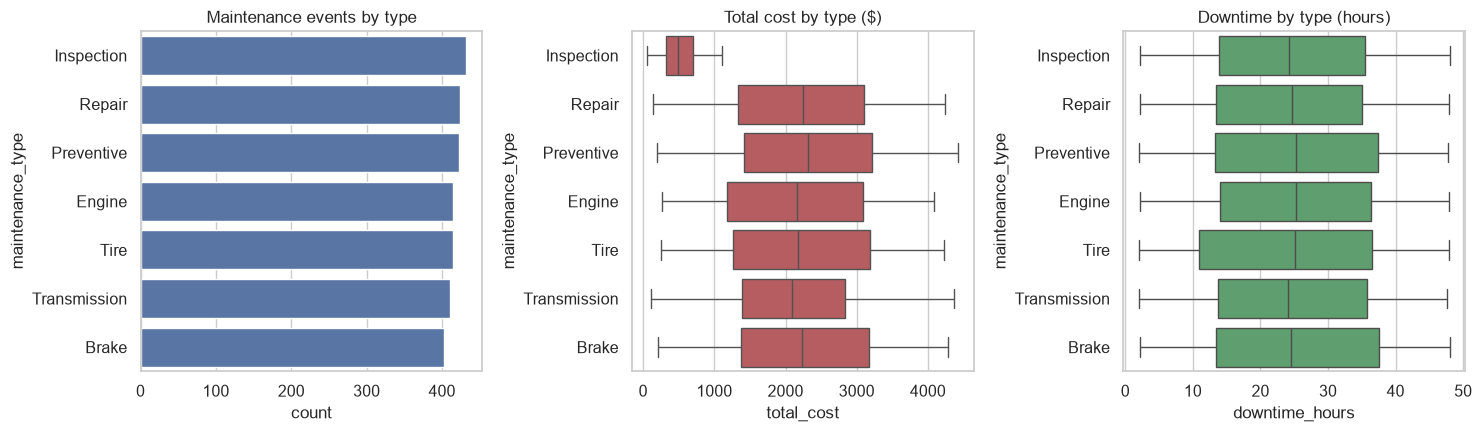

In [8]:
for col in ["odometer_reading", "labor_hours", "labor_cost", "parts_cost", "total_cost", "downtime_hours"]:
    maint[col] = pd.to_numeric(maint[col], errors="coerce")
maint["maintenance_dt"] = pd.to_datetime(maint["maintenance_date"], errors="coerce")
maint["month"] = maint["maintenance_dt"].dt.to_period("M").astype(str)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
type_order = maint["maintenance_type"].value_counts().index
sns.countplot(data=maint, y="maintenance_type", order=type_order, ax=axes[0], color="#4c72b0")
axes[0].set_title("Maintenance events by type")

sns.boxplot(data=maint, y="maintenance_type", x="total_cost", order=type_order, ax=axes[1], showfliers=False, color="#c44e52")
axes[1].set_title("Total cost by type ($)")

sns.boxplot(data=maint, y="maintenance_type", x="downtime_hours", order=type_order, ax=axes[2], showfliers=False, color="#55a868")
axes[2].set_title("Downtime by type (hours)")
plt.tight_layout()
plt.show()


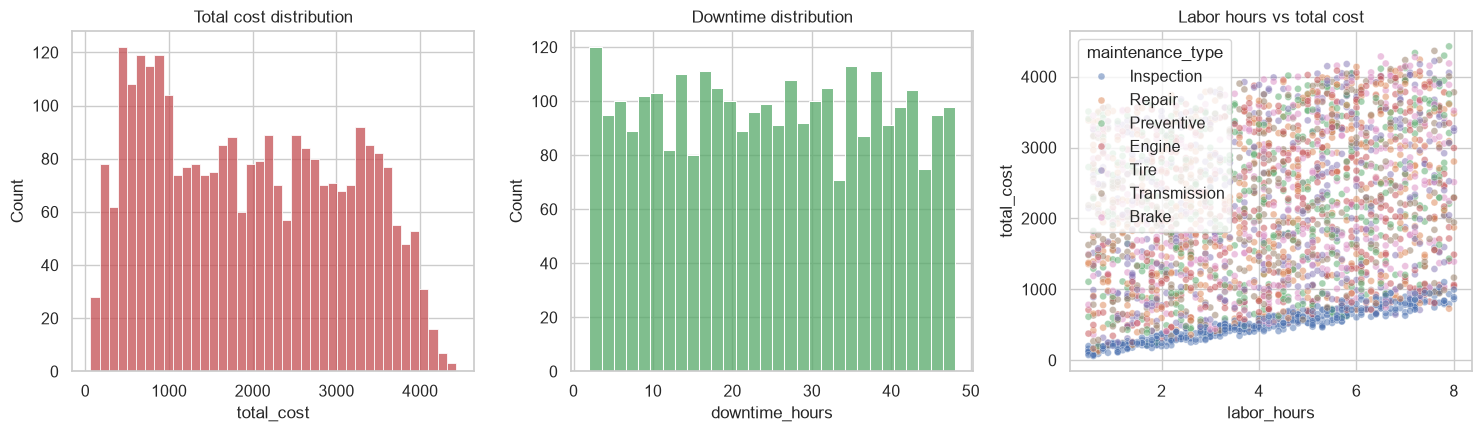

,n,avg_cost,avg_downtime,labor_share
maintenance_type,,,,
Preventive,422,"2,283.36",25.05,0.25
Brake,402,"2,267.83",24.95,0.25
Repair,424,"2,229.66",24.65,0.25
Tire,414,"2,220.80",24.36,0.25
Engine,415,"2,145.87",25.05,0.28
Transmission,411,"2,140.20",24.42,0.24
Inspection,432,510.14,24.67,0.81


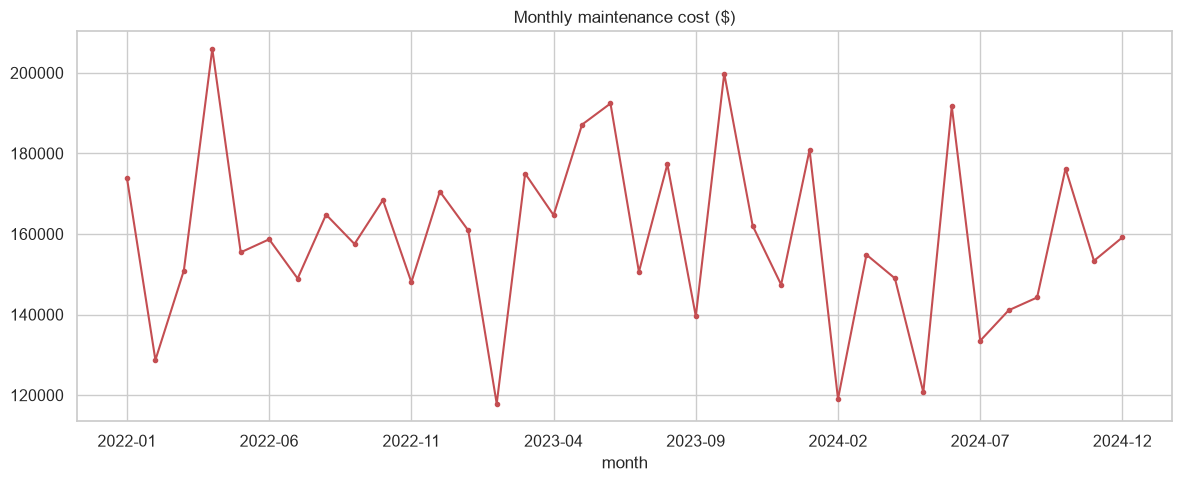

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.histplot(data=maint, x="total_cost", bins=40, ax=axes[0], color="#c44e52")
axes[0].set_title("Total cost distribution")
sns.histplot(data=maint, x="downtime_hours", bins=30, ax=axes[1], color="#55a868")
axes[1].set_title("Downtime distribution")
sns.scatterplot(data=maint, x="labor_hours", y="total_cost", hue="maintenance_type",
                alpha=0.5, s=25, ax=axes[2], hue_order=type_order)
axes[2].set_title("Labor hours vs total cost")
plt.tight_layout()
plt.show()

cost_by_type = maint.groupby("maintenance_type").agg(
    n=("maintenance_id", "count"),
    avg_cost=("total_cost", "mean"),
    avg_downtime=("downtime_hours", "mean"),
    labor_share=("labor_cost", lambda s: (s / maint.loc[s.index, "total_cost"]).mean()),
).round(2).sort_values("avg_cost", ascending=False)
display(cost_by_type)

monthly_cost = maint.groupby("month").agg(cost=("total_cost", "sum"), downtime=("downtime_hours", "sum"))
ax = monthly_cost["cost"].plot(figsize=FIGSIZE, color="#c44e52", marker="o", markersize=3)
ax.set_title("Monthly maintenance cost ($)")
plt.tight_layout()
plt.show()


## 6. Safety incidents

Small collection (170) — treat rates carefully; focus on mix and claim severity.


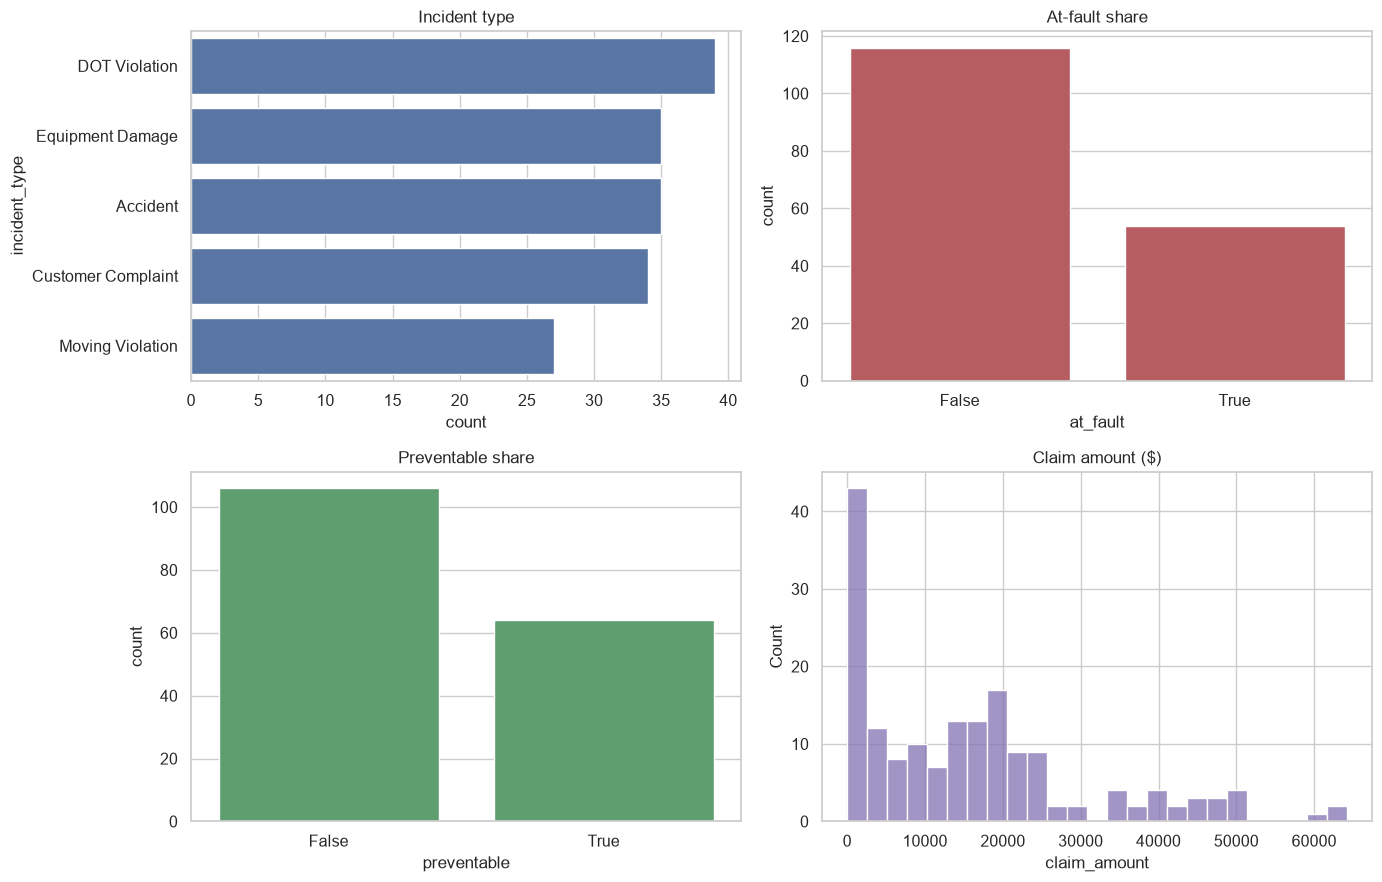

At-fault: {False: 116, True: 54}
Preventable: {False: 106, True: 64}
Injury: {False: 137, True: 33}
Claim total: $2,653,172 | mean: $15,607


In [10]:
for col in ["vehicle_damage_cost", "cargo_damage_cost", "claim_amount"]:
    safety[col] = pd.to_numeric(safety[col], errors="coerce")
safety["incident_dt"] = pd.to_datetime(safety["incident_date"], errors="coerce")
safety["at_fault"] = safety["at_fault_flag"].str.lower().map({"true": True, "false": False})
safety["preventable"] = safety["preventable_flag"].str.lower().map({"true": True, "false": False})
safety["injury"] = safety["injury_flag"].str.lower().map({"true": True, "false": False})

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.countplot(data=safety, y="incident_type", order=safety["incident_type"].value_counts().index,
              ax=axes[0, 0], color="#4c72b0")
axes[0, 0].set_title("Incident type")

sns.countplot(data=safety, x="at_fault", ax=axes[0, 1], color="#c44e52")
axes[0, 1].set_title("At-fault share")

sns.countplot(data=safety, x="preventable", ax=axes[1, 0], color="#55a868")
axes[1, 0].set_title("Preventable share")

sns.histplot(data=safety, x="claim_amount", bins=25, ax=axes[1, 1], color="#8172b2")
axes[1, 1].set_title("Claim amount ($)")
plt.tight_layout()
plt.show()

print("At-fault:", safety["at_fault"].value_counts(dropna=False).to_dict())
print("Preventable:", safety["preventable"].value_counts(dropna=False).to_dict())
print("Injury:", safety["injury"].value_counts(dropna=False).to_dict())
print("Claim total:", f"${safety['claim_amount'].sum():,.0f}", "| mean:", f"${safety['claim_amount'].mean():,.0f}")


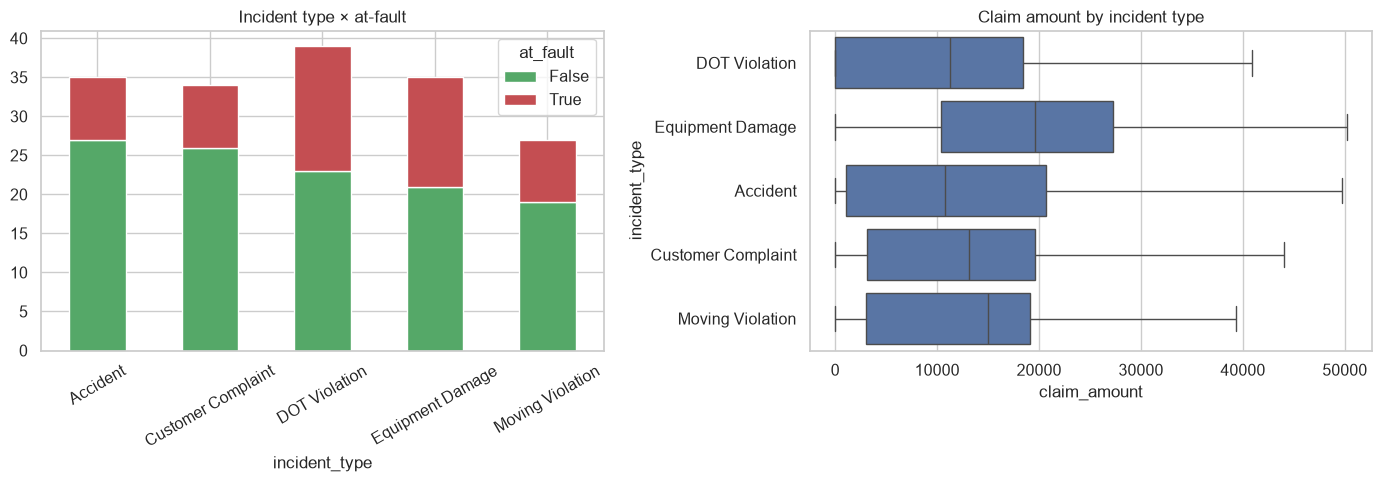

Mean claim by at-fault:


,count,mean,sum
at_fault,,,
False,116,"14,907.00","1,729,253.00"
True,54,"17,110.00","923,919.00"


Preventable claim mean: 14132.0
Not-preventable claim mean: 16497.0


In [11]:
# Severity cross-tab: type × at-fault, and claim by type
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ct = pd.crosstab(safety["incident_type"], safety["at_fault"])
ct.plot(kind="bar", stacked=True, ax=axes[0], color=["#55a868", "#c44e52"])
axes[0].set_title("Incident type × at-fault")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="at_fault")

sns.boxplot(data=safety, y="incident_type", x="claim_amount", order=safety["incident_type"].value_counts().index,
            ax=axes[1], showfliers=False, color="#4c72b0")
axes[1].set_title("Claim amount by incident type")
plt.tight_layout()
plt.show()

# Cost components
safety["total_damage"] = safety["vehicle_damage_cost"].fillna(0) + safety["cargo_damage_cost"].fillna(0)
print("Mean claim by at-fault:")
display(safety.groupby("at_fault")["claim_amount"].agg(["count", "mean", "sum"]).round(0))
print("Preventable claim mean:", round(safety.loc[safety["preventable"], "claim_amount"].mean(), 0))
print("Not-preventable claim mean:", round(safety.loc[~safety["preventable"], "claim_amount"].mean(), 0))


## 7. Cross-store sanity (Mongo → MySQL)

Delivery events reference `load_id` / `trip_id` from MySQL. Verify join coverage and compute **on-time rate by joining to drivers** — the key input to `mart_driver_performance`.


In [12]:
mysql_dir = DATA.parent / "mysql"
if not mysql_dir.exists():
    mysql_dir = Path("data/mysql")
trips = pd.read_csv(mysql_dir / "trips.csv", dtype=str)
loads = pd.read_csv(mysql_dir / "loads.csv", dtype=str)
drivers = pd.read_csv(mysql_dir / "drivers.csv", dtype=str)
routes = pd.read_csv(mysql_dir / "routes.csv", dtype=str)

# Referential coverage
ev_loads = set(events["load_id"])
ev_trips = set(events["trip_id"])
my_loads = set(loads["load_id"])
my_trips = set(trips["trip_id"])
print(f"event load_ids in MySQL loads: {len(ev_loads & my_loads):,} / {len(ev_loads):,}")
print(f"event trip_ids in MySQL trips: {len(ev_trips & my_trips):,} / {len(ev_trips):,}")
print(f"MySQL loads with zero events: {len(my_loads - ev_loads):,}")


event load_ids in MySQL loads: 85,410 / 85,410
event trip_ids in MySQL trips: 85,410 / 85,410
MySQL loads with zero events: 0


Delivery rows after join: 85410


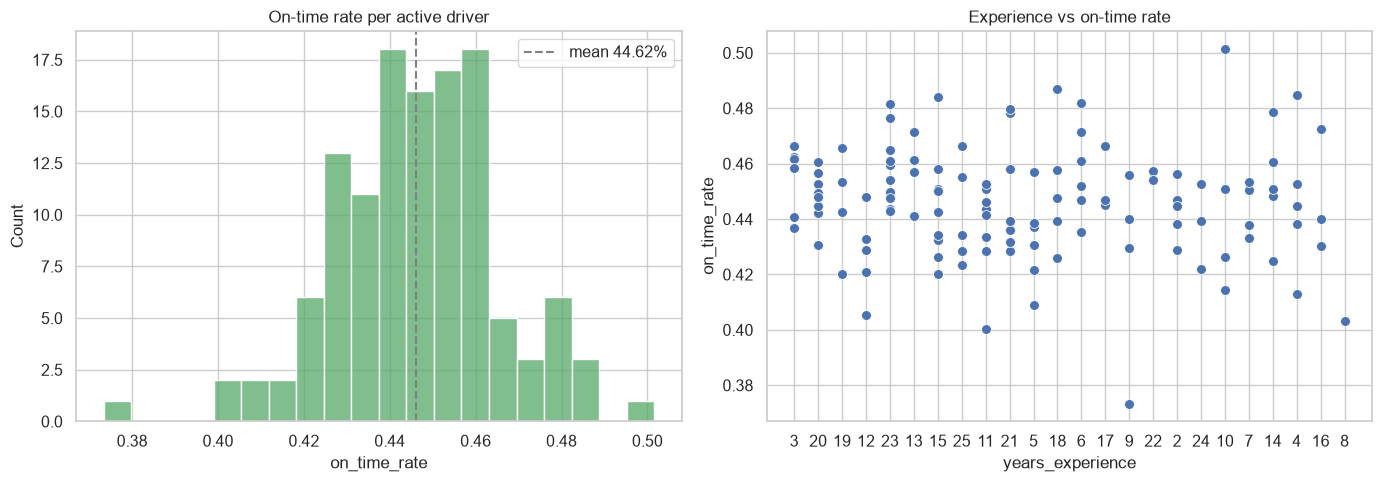

,events,on_time_rate,avg_detention
count,124.00,124.00,124.00
mean,674.97,0.45,106.67
std,29.36,0.02,2.50
min,604.00,0.37,101.56
25%,656.25,0.43,104.79
50%,678.00,0.45,106.34
75%,696.25,0.46,108.27
max,749.00,0.50,113.41


Fleet on-time (delivery): 44.61%


In [13]:
# Delivery events already carry load_id — join only driver/truck from trips
deliv = events.loc[events["event_type"] == "Delivery"].copy()
deliv = deliv.merge(trips[["trip_id", "driver_id", "truck_id"]], on="trip_id", how="inner")
print("Delivery rows after join:", len(deliv))

driver_ot = (
    deliv.groupby("driver_id")
    .agg(events=("event_id", "count"), on_time_rate=("on_time", "mean"),
         avg_detention=("detention_minutes", "mean"))
    .join(drivers.set_index("driver_id")[["employment_status", "years_experience"]])
    .query("employment_status == 'Active'")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(driver_ot["on_time_rate"], bins=20, ax=axes[0], color="#55a868")
axes[0].set_title("On-time rate per active driver")
axes[0].axvline(driver_ot["on_time_rate"].mean(), ls="--", color="gray",
                label=f"mean {driver_ot['on_time_rate'].mean():.2%}")
axes[0].legend()

sns.scatterplot(data=driver_ot, x="years_experience", y="on_time_rate", ax=axes[1], s=50, color="#4c72b0")
axes[1].set_title("Experience vs on-time rate")
plt.tight_layout()
plt.show()

display(driver_ot[["events", "on_time_rate", "avg_detention"]].describe().round(3))
print(f"Fleet on-time (delivery): {deliv['on_time'].mean():.2%}")


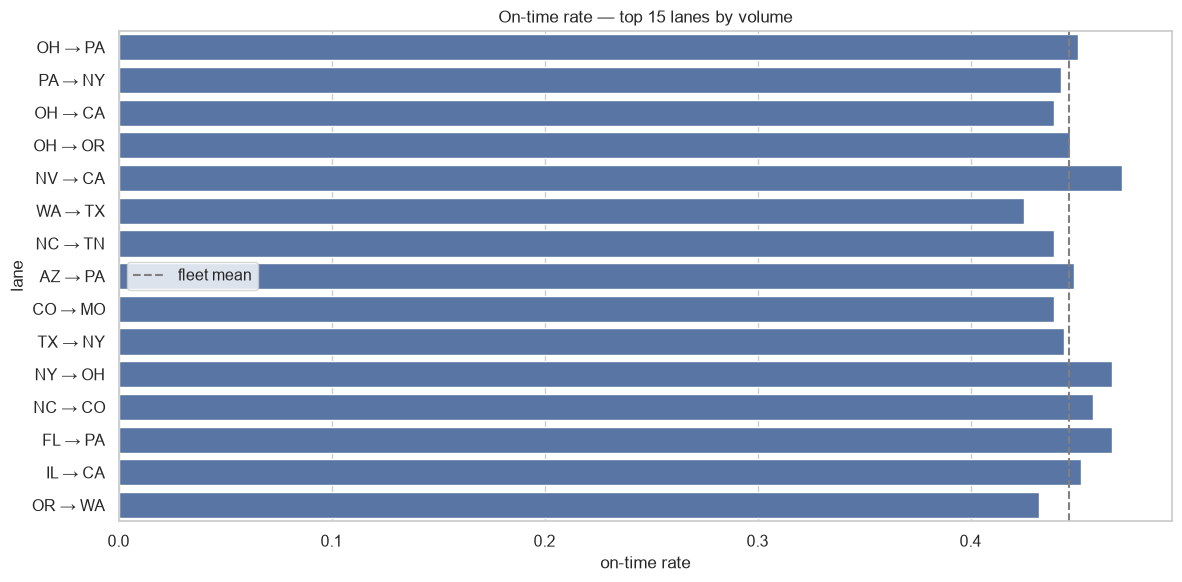

,deliveries,on_time_rate,avg_detention
lane,,,
OH → PA,1628,0.45,105.26
PA → NY,1537,0.44,108.13
OH → CA,1534,0.44,104.81
OH → OR,1525,0.45,108.31
NV → CA,1522,0.47,105.88
WA → TX,1518,0.42,106.82
NC → TN,1514,0.44,107.48
AZ → PA,1507,0.45,106.32
CO → MO,1505,0.44,105.33


In [14]:
# Route-level on-time for profitability join
deliv2 = deliv.merge(loads[["load_id", "route_id", "revenue"]], on="load_id", how="left")
deliv2 = deliv2.merge(routes[["route_id", "origin_state", "destination_state"]], on="route_id", how="left")
deliv2["lane"] = deliv2["origin_state"] + " → " + deliv2["destination_state"]

lane_ot = deliv2.groupby("lane").agg(
    deliveries=("event_id", "count"),
    on_time_rate=("on_time", "mean"),
    avg_detention=("detention_minutes", "mean"),
).sort_values("deliveries", ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
top = lane_ot.head(15)
sns.barplot(y=top.index, x=top["on_time_rate"], ax=ax, color="#4c72b0")
ax.axvline(deliv2["on_time"].mean(), ls="--", color="gray", label="fleet mean")
ax.set_title("On-time rate — top 15 lanes by volume")
ax.set_xlabel("on-time rate")
ax.legend()
plt.tight_layout()
plt.show()

display(lane_ot.head(10).round(3))


## 8. Mongo EDA — summary

See `docs/FINDING.md` for the consolidated write-up across both notebooks.


In [15]:
print("Collections:", 3)
print("Docs:", f"{len(events) + len(maint) + len(safety):,}")
print(f"On-time (delivery): {events.loc[events.event_type == 'Delivery', 'on_time'].mean():.2%}")
print(f"Mean detention: {events['detention_minutes'].mean():.1f} min")
print(f"Maintenance cost: ${maint['total_cost'].sum():,.0f} | downtime {maint['downtime_hours'].sum():,.0f} h")
print(f"Safety claims: ${safety['claim_amount'].sum():,.0f}")


Collections: 3
Docs: 173,910
On-time (delivery): 44.61%
Mean detention: 91.5 min
Maintenance cost: $5,730,573 | downtime 72,230 h
Safety claims: $2,653,172
